# DATA 475 Final Project - Report 2: Cluster Analysis
NYPD Stop, Question and Frisk data, 2012

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score)

SEED = 42
COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd', '#8c564b', '#17becf']

os.makedirs('figures', exist_ok=True)
os.makedirs('tables', exist_ok=True)
plt.rcParams.update({'font.size': 10, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})

## 1. Data preparation

In [2]:
df = pd.read_csv('2012_SQF_Data.csv', low_memory=False)
print('Raw data:', df.shape)

cs_cols = [c for c in df.columns if c.startswith('cs_')]     # reasons for stop
pf_cols = [c for c in df.columns if c.startswith('pf_')]     # physical force
weapon_cols = ['pistol', 'riflshot', 'asltweap', 'knifcuti', 'machgun', 'othrweap']
outcome_cols = ['arstmade', 'sumissue', 'frisked', 'searched']
yn_cols = cs_cols + pf_cols + weapon_cols + outcome_cols

# keep only the columns the clustering needs
keep = ['pct', 'city', 'timestop', 'xcoord', 'ycoord', 'detailcm', 'race'] + yn_cols
df = df[keep].copy()

# numbers are stored as text with stray spaces in some columns
for c in ['pct', 'timestop', 'xcoord', 'ycoord', 'detailcm']:
    df[c] = pd.to_numeric(df[c].astype(str).str.strip(), errors='coerce')

# Y/N flags become 1/0
for c in yn_cols:
    df[c] = (df[c] == 'Y').astype(int)

Raw data: (532911, 112)


New combined variables

In [3]:
# new combined variables
df['hour'] = df['timestop'] // 100
df['period'] = pd.cut(df['hour'], [-1, 5, 11, 17, 23],
                      labels=['Night', 'Morning', 'Afternoon', 'Evening'])
df['night'] = ((df['hour'] >= 18) | (df['hour'] < 6)).astype(int)
df['n_reasons'] = df[cs_cols].sum(axis=1)
df['force_used'] = df[pf_cols].max(axis=1)
df['weapon_found'] = df[weapon_cols].max(axis=1)

new_vars = ['hour', 'night', 'n_reasons', 'force_used', 'weapon_found']
print(df[new_vars].describe().T[['min', 'max', 'mean']].round(3))

              min   max    mean
hour          0.0  23.0  13.888
night         0.0   1.0   0.614
n_reasons     1.0   9.0   1.711
force_used    0.0   1.0   0.173
weapon_found  0.0   1.0   0.012


## Helper functions

In [4]:
def test_k(X, k_values, sample):
    # fit K-means for each k, return inertia and silhouette
    rows = []
    for k in k_values:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        sil = silhouette_score(X[sample], km.labels_[sample])
        rows.append([k, km.inertia_, sil])
    return pd.DataFrame(rows, columns=['k', 'inertia', 'silhouette'])


def plot_k(res, chosen_k, filename):
    # elbow plot and silhouette plot side by side
    fig, ax = plt.subplots(1, 2, figsize=(6.5, 2.4))
    ax[0].plot(res['k'], res['inertia'], marker='o', color=COLORS[0])
    ax[0].set_xlabel('Number of clusters (k)')
    ax[0].set_ylabel('Within-cluster sum of squares')
    ax[0].set_title('Elbow method', fontsize=10)
    ax[1].plot(res['k'], res['silhouette'], marker='o', color=COLORS[1])
    ax[1].set_xlabel('Number of clusters (k)')
    ax[1].set_ylabel('Average silhouette score')
    ax[1].set_title('Silhouette method', fontsize=10)
    for a in ax:
        a.axvline(chosen_k, color='grey', linestyle='--')
        a.set_xticks(res['k'])
    fig.tight_layout()
    fig.savefig(filename)
    plt.show()


def relabel_by_size(labels):
    # cluster 1 = largest cluster, cluster 2 = second largest, and so on
    order = pd.Series(labels).value_counts().index
    mapping = {old: new + 1 for new, old in enumerate(order)}
    return pd.Series(labels).map(mapping).values


def validation(X, labels):
    return [silhouette_score(X, labels),
            davies_bouldin_score(X, labels),
            calinski_harabasz_score(X, labels)]


rng = np.random.RandomState(SEED)
validation_rows = []

## 2. Model 1: Location of robbery stops

In [5]:
rob = df[df['detailcm'] == 85].copy()          # 85 = robbery in the file spec
print('Robbery stops:', len(rob))
rob = rob.dropna(subset=['xcoord', 'ycoord'])
print('Robbery stops with coordinates:', len(rob))

X_rob = rob[['xcoord', 'ycoord']].values       # NY State Plane coordinates in feet
sample_rob = rng.choice(len(X_rob), 10000, replace=False)

Robbery stops: 116843
Robbery stops with coordinates: 113734


### 2a. K-means zones
Choose k with the elbow and silhouette methods

     k       inertia  silhouette
0    2  5.884601e+13       0.475
1    3  3.606863e+13       0.481
2    4  2.757623e+13       0.450
3    5  2.154974e+13       0.452
4    6  1.785083e+13       0.446
5    7  1.502904e+13       0.426
6    8  1.264977e+13       0.445
7    9  1.069903e+13       0.459
8   10  9.596205e+12       0.457
9   11  8.490865e+12       0.448
10  12  7.693568e+12       0.443


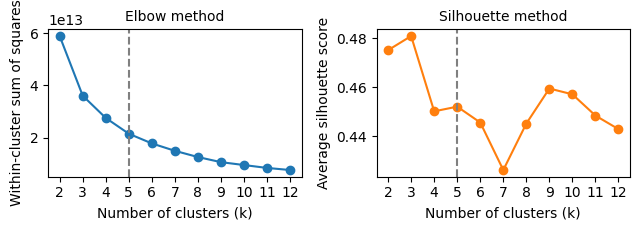

In [6]:
res_rob = test_k(X_rob, range(2, 13), sample_rob)
res_rob.to_csv('tables/k_selection_robbery.csv', index=False)
print(res_rob.round(3))
K_ROB = 5
plot_k(res_rob, K_ROB, 'figures/fig1_k_robbery.png')

Fit the final model and profile the zones

In [7]:
km_rob = KMeans(n_clusters=K_ROB, n_init=10, random_state=SEED).fit(X_rob)
rob['zone'] = relabel_by_size(km_rob.labels_)
validation_rows.append(['Robbery zones (K-means)', K_ROB] +
                       validation(X_rob[sample_rob], rob['zone'].values[sample_rob]))

zones = rob.groupby('zone').agg(stops=('zone', 'size'),
                                x_center=('xcoord', 'mean'),
                                y_center=('ycoord', 'mean'),
                                main_borough=('city', lambda s: s.mode()[0]),
                                night_share=('night', 'mean'))
zones['share'] = zones['stops'] / len(rob)
by_period = pd.crosstab(rob['zone'], rob['period'], normalize='columns')
zones = zones.join(by_period)
zones.to_csv('tables/robbery_zones.csv')
print(zones.round(3))
print(pd.crosstab(rob['zone'], rob['city']))
print(rob['period'].value_counts())

      stops     x_center    y_center main_borough  night_share  share  Night  \
zone                                                                           
1     42100  1004734.504  188387.087     BROOKLYN        0.670  0.370  0.376   
2     25141  1008826.471  242502.303        BRONX        0.612  0.221  0.215   
3     17387   987907.968  167680.826     BROOKLYN        0.639  0.153  0.125   
4     14609  1040932.838  188551.262       QUEENS        0.608  0.128  0.096   
5     14497  1019950.260  213373.202       QUEENS        0.653  0.127  0.187   

      Morning  Afternoon  Evening  
zone                               
1       0.346      0.340    0.391  
2       0.247      0.238    0.208  
3       0.123      0.163    0.165  
4       0.146      0.139    0.134  
5       0.137      0.120    0.102  
city  BRONX  BROOKLYN  MANHATTAN  QUEENS  STATEN IS
zone                                               
1         0     37081       3265    1754          0
2     15597         0       954

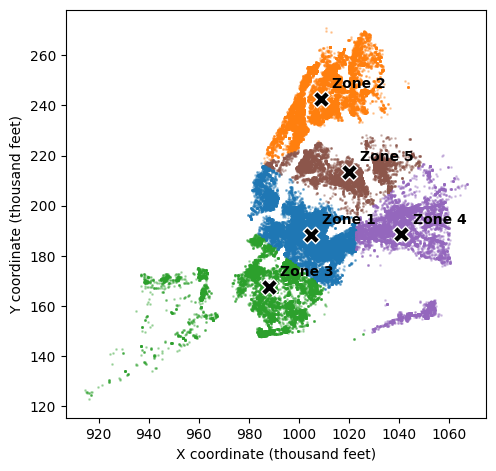

In [8]:
fig, ax = plt.subplots(figsize=(5.6, 5.3))
for z in range(1, K_ROB + 1):
    part = rob[rob['zone'] == z]
    ax.scatter(part['xcoord'] / 1000, part['ycoord'] / 1000, s=1, alpha=0.3,
               color=COLORS[z - 1])
    ax.scatter(zones.loc[z, 'x_center'] / 1000, zones.loc[z, 'y_center'] / 1000,
               marker='X', s=140, color='black', edgecolor='white')
    ax.annotate('Zone ' + str(z),
                (zones.loc[z, 'x_center'] / 1000, zones.loc[z, 'y_center'] / 1000),
                xytext=(8, 8), textcoords='offset points', fontweight='bold')
ax.set_xlabel('X coordinate (thousand feet)')
ax.set_ylabel('Y coordinate (thousand feet)')
ax.set_aspect('equal')
fig.savefig('figures/fig2_robbery_zones.png')
plt.show()

### 2b. DBSCAN hotspots
Test four search radii

In [9]:
# eps = 750 feet (about three short city blocks)
# min_samples = 0.25% of the stops being clustered
EPS = 750
MIN_SHARE = 0.0025

rows = []
for eps in [500, 750, 1000, 1500]:
    labels = DBSCAN(eps=eps, min_samples=int(MIN_SHARE * len(X_rob))).fit(X_rob).labels_
    rows.append([eps, int(MIN_SHARE * len(X_rob)), labels.max() + 1, (labels >= 0).mean(),
                 np.bincount(labels[labels >= 0]).max()])
dbscan_tests = pd.DataFrame(rows, columns=['eps_feet', 'min_samples', 'hotspots',
                                           'share_in_hotspots', 'largest_hotspot'])
dbscan_tests.to_csv('tables/dbscan_sensitivity.csv', index=False)
print(dbscan_tests.round(3))

   eps_feet  min_samples  hotspots  share_in_hotspots  largest_hotspot
0       500          284        20              0.130             2682
1       750          284        28              0.311             4134
2      1000          284        33              0.505            17525
3      1500          284        35              0.766            34464


Final hotspots at 750 feet

In [10]:
db = DBSCAN(eps=EPS, min_samples=int(MIN_SHARE * len(X_rob))).fit(X_rob)
rob['hotspot'] = db.labels_
in_hot = rob['hotspot'] >= 0
print('Hotspots:', rob['hotspot'].max() + 1, 'share of stops:', round(in_hot.mean(), 3))
print('Night share, all robbery stops:', round(rob['night'].mean(), 3))

hot_sample = rng.choice(in_hot.sum(), 10000, replace=False)
validation_rows.append(['Robbery hotspots (DBSCAN)', rob['hotspot'].max() + 1] +
                       validation(X_rob[in_hot][hot_sample], rob['hotspot'][in_hot].values[hot_sample]))

hotspots = rob[in_hot].groupby('hotspot').agg(stops=('hotspot', 'size'),
                                              precinct=('pct', lambda s: s.mode()[0]),
                                              borough=('city', lambda s: s.mode()[0]),
                                              night_share=('night', 'mean'))
hotspots = hotspots.sort_values('stops', ascending=False)
hotspots.to_csv('tables/robbery_hotspots.csv')
print(hotspots.head(10).round(3))

Hotspots: 28 share of stops: 0.311
Night share, all robbery stops: 0.642


         stops  precinct   borough  night_share
hotspot                                        
13        4134       110    QUEENS        0.810
4         4127        73  BROOKLYN        0.630
3         3344        70  BROOKLYN        0.688
1         3133        90  BROOKLYN        0.613
16        2591        83  BROOKLYN        0.841
2         1974        44     BRONX        0.586
7         1950        75  BROOKLYN        0.515
14        1837        83  BROOKLYN        0.841
0         1656        81  BROOKLYN        0.596
17        1344       109    QUEENS        0.348


Day versus night hotspots

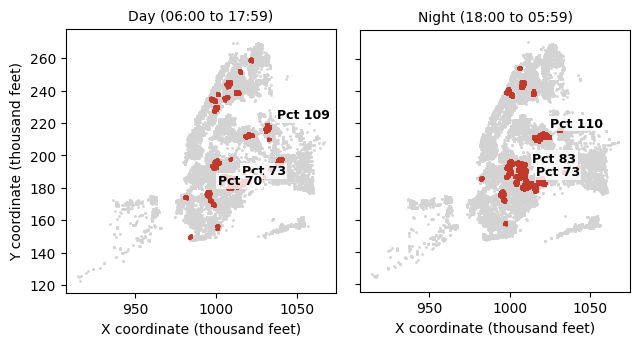

                   period  stops  hotspots  share_in_hotspots  \
0    Day (06:00 to 17:59)  40662        41              0.330   
1  Night (18:00 to 05:59)  73072        34              0.354   

        top5_precincts  
0  73, 70, 109, 75, 44  
1  110, 73, 83, 70, 79  


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(6.5, 3.4), sharey=True)
day_night = []
for i, (name, flag) in enumerate([('Day (06:00 to 17:59)', 0), ('Night (18:00 to 05:59)', 1)]):
    part = rob[rob['night'] == flag].copy()
    Xp = part[['xcoord', 'ycoord']].values
    part['hot'] = DBSCAN(eps=EPS, min_samples=int(MIN_SHARE * len(Xp))).fit(Xp).labels_
    hot = part[part['hot'] >= 0]
    top = hot.groupby('hot').agg(stops=('hot', 'size'), x=('xcoord', 'mean'), y=('ycoord', 'mean'),
                                 precinct=('pct', lambda s: s.mode()[0]))
    top = top.sort_values('stops', ascending=False).head(5)
    day_night.append([name, len(part), part['hot'].max() + 1, len(hot) / len(part),
                      ', '.join(top['precinct'].astype(int).astype(str))])

    cold = part[part['hot'] < 0]
    ax[i].scatter(cold['xcoord'] / 1000, cold['ycoord'] / 1000, s=1, color='lightgrey')
    ax[i].scatter(hot['xcoord'] / 1000, hot['ycoord'] / 1000, s=1, color='#c0392b')
    # label the three biggest hotspots with their precinct number
    for _, r in top.head(3).iterrows():
        ax[i].annotate('Pct ' + str(int(r['precinct'])), (r['x'] / 1000, r['y'] / 1000),
                       xytext=(7, 7), textcoords='offset points', fontsize=9, fontweight='bold',
                       bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=1))
    ax[i].set_title(name, fontsize=10)
    ax[i].set_xlabel('X coordinate (thousand feet)')
    ax[i].set_aspect('equal')
ax[0].set_ylabel('Y coordinate (thousand feet)')
fig.tight_layout()
fig.savefig('figures/fig3_robbery_hotspots.png')
plt.show()

day_night = pd.DataFrame(day_night, columns=['period', 'stops', 'hotspots', 'share_in_hotspots', 'top5_precincts'])
day_night.to_csv('tables/hotspots_day_night.csv', index=False)
print(day_night.round(3))

## 3. Model 2: Reasons for stop

    k     inertia  silhouette
0   2  502844.635       0.259
1   3  430374.275       0.291
2   4  368602.654       0.340
3   5  331965.347       0.370
4   6  301762.659       0.378
5   7  266993.449       0.432
6   8  238398.753       0.471
7   9  221337.223       0.490
8  10  204418.055       0.514


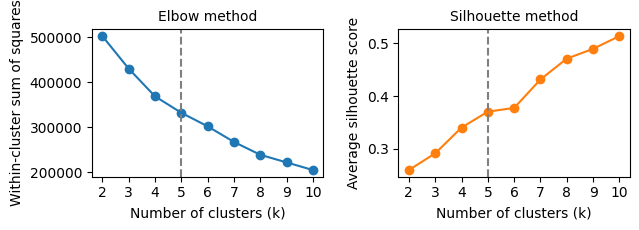

In [12]:
reason_names = {'cs_objcs': 'Suspicious object', 'cs_descr': 'Fits description',
                'cs_casng': 'Casing', 'cs_lkout': 'Acting as lookout',
                'cs_cloth': 'Crime clothing', 'cs_drgtr': 'Drug transaction',
                'cs_furtv': 'Furtive movements', 'cs_vcrim': 'Violent crime actions',
                'cs_bulge': 'Suspicious bulge', 'cs_other': 'Other'}

X_cs = df[cs_cols].values
sample_cs = rng.choice(len(X_cs), 10000, replace=False)

res_cs = test_k(X_cs, range(2, 11), sample_cs)
res_cs.to_csv('tables/k_selection_reasons.csv', index=False)
print(res_cs.round(3))
K_CS = 5
plot_k(res_cs, K_CS, 'figures/fig4_k_reasons.png')

Fit the final model and profile the clusters

In [13]:
km_cs = KMeans(n_clusters=K_CS, n_init=10, random_state=SEED).fit(X_cs)
df['reason_cluster'] = relabel_by_size(km_cs.labels_)
validation_rows.append(['Reasons for stop (K-means)', K_CS] +
                       validation(X_cs[sample_cs], df['reason_cluster'].values[sample_cs]))

# centroid = share of stops in the cluster that list each reason
centers = df.groupby('reason_cluster')[cs_cols].mean().rename(columns=reason_names)
centers.to_csv('tables/reason_centroids.csv')
print(centers.round(2))

profile = df.groupby('reason_cluster').agg(stops=('pct', 'size'),
                                           avg_reasons=('n_reasons', 'mean'),
                                           frisk_rate=('frisked', 'mean'),
                                           force_rate=('force_used', 'mean'),
                                           arrest_rate=('arstmade', 'mean'),
                                           weapon_rate=('weapon_found', 'mean'))
profile['share'] = profile['stops'] / len(df)
profile.to_csv('tables/reason_profile.csv')
print(profile.round(3))
print(df[['n_reasons', 'frisked', 'force_used', 'arstmade', 'weapon_found']].mean().round(3))

race_mix = pd.crosstab(df['reason_cluster'], df['race'], normalize='index')
race_mix.to_csv('tables/reason_race_mix.csv')
print(race_mix.round(3))

                Suspicious object  Fits description  Casing  \
reason_cluster                                                
1                            0.02              0.00    0.24   
2                            0.06              0.00    0.59   
3                            0.01              0.05    0.70   
4                            0.01              1.00    0.12   
5                            0.02              0.11    0.07   

                Acting as lookout  Crime clothing  Drug transaction  \
reason_cluster                                                        
1                            0.00            0.06              0.08   
2                            0.00            0.04              0.12   
3                            1.00            0.06              0.07   
4                            0.04            0.04              0.03   
5                            0.02            0.01              0.03   

                Furtive movements  Violent crime actions  Su

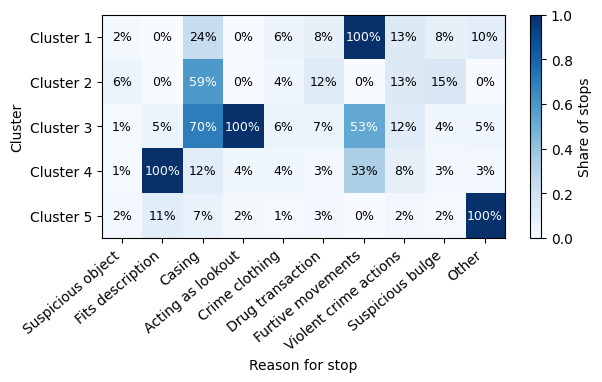

In [14]:
# heatmap of the centroids
fig, ax = plt.subplots(figsize=(6.5, 2.9))
im = ax.imshow(centers.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(centers.columns)))
ax.set_xticklabels(centers.columns, rotation=40, ha='right')
ax.set_yticks(range(K_CS))
ax.set_yticklabels(['Cluster ' + str(c) for c in centers.index])
for i in range(centers.shape[0]):
    for j in range(centers.shape[1]):
        v = centers.values[i, j]
        ax.text(j, i, format(v, '.0%'), ha='center', va='center',
                color='white' if v > 0.5 else 'black', fontsize=9)
ax.set_xlabel('Reason for stop')
ax.set_ylabel('Cluster')
fig.colorbar(im, label='Share of stops')
fig.savefig('figures/fig5_reason_heatmap.png')
plt.show()

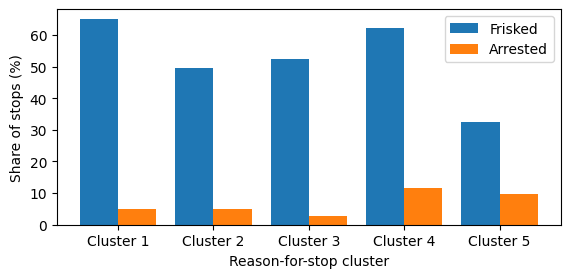

In [15]:
# frisk rate against arrest rate by cluster
fig, ax = plt.subplots(figsize=(6.5, 2.8))
pos = np.arange(K_CS)
ax.bar(pos - 0.2, profile['frisk_rate'] * 100, width=0.4, color=COLORS[0], label='Frisked')
ax.bar(pos + 0.2, profile['arrest_rate'] * 100, width=0.4, color=COLORS[1], label='Arrested')
ax.set_xticks(pos)
ax.set_xticklabels(['Cluster ' + str(c) for c in profile.index])
ax.set_xlabel('Reason-for-stop cluster')
ax.set_ylabel('Share of stops (%)')
ax.legend()
fig.savefig('figures/fig6_reason_outcomes.png')
plt.show()

## 4. Model 3: Precinct profiles

Precincts: 76
                 min        max      mean
stops        592.000  24408.000  7011.987
frisk_rate     0.273      0.814     0.531
force_rate     0.033      0.433     0.169
arrest_rate    0.014      0.191     0.067
weapon_rate    0.003      0.051     0.012
   k  inertia  silhouette
0  2  154.112       0.289
1  3  106.654       0.326
2  4   85.901       0.278
3  5   74.147       0.273
4  6   64.472       0.280
5  7   56.643       0.264
6  8   51.401       0.257


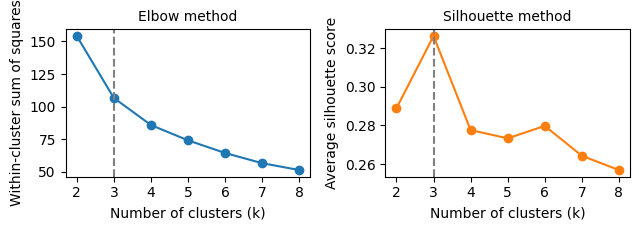

In [16]:
pct = df.groupby('pct').agg(stops=('pct', 'size'),
                            frisk_rate=('frisked', 'mean'),
                            force_rate=('force_used', 'mean'),
                            arrest_rate=('arstmade', 'mean'),
                            weapon_rate=('weapon_found', 'mean'),
                            borough=('city', lambda s: s.mode()[0]))
print('Precincts:', len(pct))
print(pct.describe().T[['min', 'max', 'mean']].round(3))

features = ['frisk_rate', 'force_rate', 'arrest_rate']
X_pct = StandardScaler().fit_transform(pct[features])

res_pct = test_k(X_pct, range(2, 9), np.arange(len(X_pct)))
res_pct.to_csv('tables/k_selection_precincts.csv', index=False)
print(res_pct.round(3))
K_PCT = 3
plot_k(res_pct, K_PCT, 'figures/fig7_k_precincts.png')

Fit the final model and profile the clusters

In [17]:
km_pct = KMeans(n_clusters=K_PCT, n_init=10, random_state=SEED).fit(X_pct)
pct['cluster'] = relabel_by_size(km_pct.labels_)
validation_rows.append(['Precinct profiles (K-means)', K_PCT] + validation(X_pct, pct['cluster'].values))

pct_profile = pct.groupby('cluster').agg(precincts=('stops', 'size'),
                                         total_stops=('stops', 'sum'),
                                         avg_stops=('stops', 'mean'),
                                         frisk_rate=('frisk_rate', 'mean'),
                                         force_rate=('force_rate', 'mean'),
                                         arrest_rate=('arrest_rate', 'mean'),
                                         weapon_rate=('weapon_rate', 'mean'))
pct_profile.to_csv('tables/precinct_profile.csv')
pct.to_csv('tables/precinct_clusters.csv')
print(pct_profile.round(3))
print(pd.crosstab(pct['cluster'], pct['borough']))

         precincts  total_stops  avg_stops  frisk_rate  force_rate  \
cluster                                                              
1               35       271982   7770.914       0.494       0.106   
2               21        95423   4543.952       0.465       0.186   
3               20       165506   8275.300       0.664       0.263   

         arrest_rate  weapon_rate  
cluster                            
1              0.049        0.012  
2              0.103        0.016  
3              0.061        0.010  
borough  BRONX  BROOKLYN  MANHATTAN  QUEENS  STATEN IS
cluster                                               
1            2        19          6       5          3
2            2         1         14       4          0
3            8         3          2       7          0


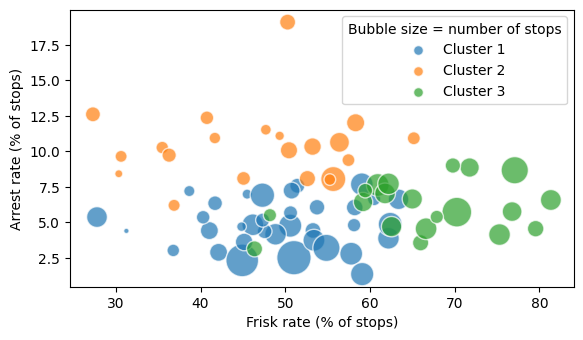

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for c in range(1, K_PCT + 1):
    part = pct[pct['cluster'] == c]
    ax.scatter(part['frisk_rate'] * 100, part['arrest_rate'] * 100, s=part['stops'] / 40,
               color=COLORS[c - 1], alpha=0.7, edgecolor='white', label='Cluster ' + str(c))
ax.set_xlabel('Frisk rate (% of stops)')
ax.set_ylabel('Arrest rate (% of stops)')
legend = ax.legend(title='Bubble size = number of stops')
for handle in legend.legend_handles:
    handle.set_sizes([50])
fig.savefig('figures/fig8_precinct_clusters.png')
plt.show()

## 5. Internal validation

In [19]:
val = pd.DataFrame(validation_rows, columns=['model', 'clusters', 'silhouette',
                                             'davies_bouldin', 'calinski_harabasz'])
val.to_csv('tables/validation.csv', index=False)
print(val.round(3))

                         model  clusters  silhouette  davies_bouldin  \
0      Robbery zones (K-means)         5       0.452           0.785   
1    Robbery hotspots (DBSCAN)        28       0.609           0.487   
2   Reasons for stop (K-means)         5       0.370           1.281   
3  Precinct profiles (K-means)         3       0.326           1.045   

   calinski_harabasz  
0          11469.088  
1          92564.059  
2           2324.501  
3             41.528  


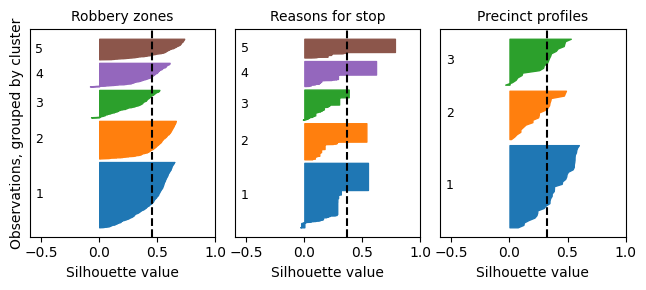

In [20]:
# silhouette plots for the three K-means models
plot_data = [('Robbery zones', X_rob[sample_rob][:3000], rob['zone'].values[sample_rob][:3000]),
             ('Reasons for stop', X_cs[sample_cs][:3000], df['reason_cluster'].values[sample_cs][:3000]),
             ('Precinct profiles', X_pct, pct['cluster'].values)]

fig, ax = plt.subplots(1, 3, figsize=(6.5, 3.0), sharex=True)
for i, (name, X, labels) in enumerate(plot_data):
    sil = silhouette_samples(X, labels)
    y = 0
    for c in np.unique(labels):
        vals = np.sort(sil[labels == c])
        ax[i].fill_betweenx(np.arange(y, y + len(vals)), 0, vals, color=COLORS[c - 1])
        ax[i].text(-0.55, y + len(vals) / 2, str(c), va='center', fontsize=9)
        y += len(vals) + len(X) * 0.02
    ax[i].axvline(sil.mean(), color='black', linestyle='--')
    ax[i].set_title(name, fontsize=10)
    ax[i].set_xlabel('Silhouette value')
    ax[i].set_yticks([])
    ax[i].set_xlim(-0.6, 1)
ax[0].set_ylabel('Observations, grouped by cluster')
fig.tight_layout()
fig.savefig('figures/fig9_silhouettes.png')
plt.show()